# Problem Set 5 - Comparing Recurrent Neural Networks (RNN) and Long Short-Term Memory (LSTM) models for Sequence Modeling in NLP

Name: **Jessica Mae T. Lanuzo**                | Section: **BSCS 3A**
<hr>

### Dataset used: IMDB Dataset of 50K Movie Reviews

Description from Kaggle:
- IMDB dataset having 50K movie reviews for natural language processing or Text analytics.
This is a dataset for binary sentiment classification containing substantially more data than previous benchmark datasets. We provide a set of 25,000 highly polar movie reviews for training and 25,000 for testing. So, predict the number of positive and negative reviews using either classification or deep learning algorithms.
For more dataset information, please go through the following link,
http://ai.stanford.edu/~amaas/data/sentiment/

Available at: https://www.kaggle.com/datasets/lakshmi25npathi/imdb-dataset-of-50k-movie-reviews?resource=download 

# Implementation

In [1]:
%pip install --upgrade pip
%pip uninstall -y tensorflow tensorflow-macos tensorflow-metal keras
%pip install tensorflow-macos==2.15.0 pandas nltk scikit-learn matplotlib

Note: you may need to restart the kernel to use updated packages.
Found existing installation: tensorflow-macos 2.15.0
Uninstalling tensorflow-macos-2.15.0:
  Successfully uninstalled tensorflow-macos-2.15.0
Found existing installation: keras 2.15.0
Uninstalling keras-2.15.0:
  Successfully uninstalled keras-2.15.0
Note: you may need to restart the kernel to use updated packages.
  Using cached tensorflow_macos-2.15.0-cp311-cp311-macosx_12_0_arm64.whl.metadata (4.2 kB)
  Using cached keras-2.15.0-py3-none-any.whl.metadata (2.4 kB)
Using cached tensorflow_macos-2.15.0-cp311-cp311-macosx_12_0_arm64.whl (208.8 MB)
Using cached keras-2.15.0-py3-none-any.whl (1.7 MB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [tensorflow-macos][tensorflow-macos]
Note: you may need to restart the kernel to use updated packages.


## I. Text Preprocessing

### Setting up libraries

In [2]:
import os
import re
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, LSTM, Dense
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.callbacks import EarlyStopping

print("TensorFlow version:", tf.__version__)

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

TensorFlow version: 2.15.0


[nltk_data] Downloading package punkt to
[nltk_data]     /Users/jesslanuzo/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     /Users/jesslanuzo/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/jesslanuzo/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


### Importing the dataset

In [3]:
# pd.set_option('display.max_colwidth', None)

In [4]:
# Load the IMDB dataset from the local CSV file
df = pd.read_csv("IMDB Dataset.csv")

# Normalize the sentiment labels to 0/1
df["label"] = df["sentiment"].map({"negative": 0, "positive": 1})

# Shuffle once so the split is randomized but reproducible
df = df.sample(frac=1, random_state=SEED).reset_index(drop=True)
df.head()

,review,sentiment,label
0,I really liked this Summerslam due to the look...,positive,1
1,Not many television shows appeal to quite as m...,positive,1
2,The film quickly gets to a major chase scene w...,negative,0
3,Jane Austen would definitely approve of this o...,positive,1
4,Expectations were somewhat high for me when I ...,negative,0


In [5]:
# Check the class balance
df["sentiment"].value_counts().to_frame(name="count")

,count
sentiment,
positive,25000
negative,25000


### Text Cleaning and Tokenization

In [6]:
stop_words = set(stopwords.words("english"))

def clean_and_tokenize(text):
    text = str(text).lower()
    text = re.sub(r"<br\s*/?>", " ", text)
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    tokens = word_tokenize(text)
    return tokens

df["tokens"] = df["review"].apply(clean_and_tokenize)
df["clean_text"] = df["tokens"].apply(lambda tokens: " ".join(tokens))
df[["review", "clean_text", "label"]].head()

,review,clean_text,label
0,I really liked this Summerslam due to the look...,i really liked this summerslam due to the look...,1
1,Not many television shows appeal to quite as m...,not many television shows appeal to quite as m...,1
2,The film quickly gets to a major chase scene w...,the film quickly gets to a major chase scene w...,0
3,Jane Austen would definitely approve of this o...,jane austen would definitely approve of this o...,1
4,Expectations were somewhat high for me when I ...,expectations were somewhat high for me when i ...,0


### Vocabulary Creation, Integer Encoding, and Padding

In [7]:
# Train-test split on the cleaned text so both models use the same data partition
X_train_texts, X_test_texts, y_train, y_test = train_test_split(
    df["clean_text"],
    df["label"],
    test_size=0.2,
    random_state=SEED,
    stratify=df["label"]
)

# Vocabulary creation on the training set only
max_words = 20000
max_len = 200

tokenizer = Tokenizer(num_words=max_words, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train_texts)

word_index = tokenizer.word_index
vocab_size = min(max_words, len(word_index) + 1)

# Convert text to integer sequences
X_train_sequences = tokenizer.texts_to_sequences(X_train_texts)
X_test_sequences = tokenizer.texts_to_sequences(X_test_texts)

# Pad sequences to a uniform length
X_train_padded = pad_sequences(X_train_sequences, maxlen=max_len, padding="post", truncating="post")
X_test_padded = pad_sequences(X_test_sequences, maxlen=max_len, padding="post", truncating="post")

print(f"Vocabulary size: {vocab_size:,}")
print(f"Max sequence length: {max_len}")
print(f"X_train_padded shape: {X_train_padded.shape}")
print(f"X_test_padded shape: {X_test_padded.shape}")

Vocabulary size: 20,000
Max sequence length: 200
X_train_padded shape: (40000, 200)
X_test_padded shape: (10000, 200)


## III. Model Implementation

### A. RNN-based Model

In [8]:
embedding_dim = 128
rnn_units = 64

def build_rnn_model(vocab_size, embedding_dim, max_len):
    model = Sequential([
        Embedding(input_dim=vocab_size, output_dim=embedding_dim, input_length=max_len),
        SimpleRNN(rnn_units),
        Dense(1, activation="sigmoid")
    ])
    model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    return model

rnn_model = build_rnn_model(vocab_size, embedding_dim, max_len)
rnn_model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 embedding (Embedding)       (None, 200, 128)          2560000   
                                                                 
 simple_rnn (SimpleRNN)      (None, 64)                12352     
                                                                 
 dense (Dense)               (None, 1)                 65        
                                                                 
Total params: 2572417 (9.81 MB)
Trainable params: 2572417 (9.81 MB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


### B. LSTM-based Model

In [9]:
lstm_units = 64

def build_lstm_model(vocab_size, embedding_dim, max_len):
    model = Sequential([
        Embedding(input_dim=vocab_size, output_dim=embedding_dim, input_length=max_len),
        LSTM(lstm_units),
        Dense(1, activation="sigmoid")
    ])
    model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    return model

lstm_model = build_lstm_model(vocab_size, embedding_dim, max_len)
lstm_model.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 embedding_1 (Embedding)     (None, 200, 128)          2560000   
                                                                 
 lstm (LSTM)                 (None, 64)                49408     
                                                                 
 dense_1 (Dense)             (None, 1)                 65        
                                                                 
Total params: 2609473 (9.95 MB)
Trainable params: 2609473 (9.95 MB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


## IV. Model Training

In [10]:
epochs = 5
batch_size = 64
validation_split = 0.2

def make_early_stopping():
    return EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True
    )

In [11]:
history_rnn = rnn_model.fit(
    X_train_padded,
    y_train,
    validation_split=validation_split,
    epochs=epochs,
    batch_size=batch_size,
    callbacks=[make_early_stopping()],
    verbose=1
)

history_lstm = lstm_model.fit(
    X_train_padded,
    y_train,
    validation_split=validation_split,
    epochs=epochs,
    batch_size=batch_size,
    callbacks=[make_early_stopping()],
    verbose=1
)

Epoch 1/5
500/500 [==============================] - 15s 29ms/step - loss: 0.6962 - accuracy: 0.5076 - val_loss: 0.6946 - val_accuracy: 0.5067
Epoch 2/5
500/500 [==============================] - 16s 31ms/step - loss: 0.6906 - accuracy: 0.5253 - val_loss: 0.6965 - val_accuracy: 0.5106
Epoch 3/5
500/500 [==============================] - 14s 28ms/step - loss: 0.6754 - accuracy: 0.5644 - val_loss: 0.6959 - val_accuracy: 0.5210
Epoch 1/5
500/500 [==============================] - 44s 84ms/step - loss: 0.6583 - accuracy: 0.6084 - val_loss: 0.6555 - val_accuracy: 0.6216
Epoch 2/5
500/500 [==============================] - 38s 76ms/step - loss: 0.6539 - accuracy: 0.6107 - val_loss: 0.6785 - val_accuracy: 0.5466
Epoch 3/5
500/500 [==============================] - 37s 74ms/step - loss: 0.6443 - accuracy: 0.6233 - val_loss: 0.6502 - val_accuracy: 0.6883
Epoch 4/5
500/500 [==============================] - 37s 75ms/step - loss: 0.5588 - accuracy: 0.7201 - val_loss: 0.6704 - val_accuracy: 0.5739

## V. Evaluation

In [12]:
def evaluate_model(model, X_test_data, y_test_data, model_name):
    loss, accuracy = model.evaluate(X_test_data, y_test_data, verbose=0)
    y_prob = model.predict(X_test_data, verbose=0).ravel()
    y_pred = (y_prob >= 0.5).astype(int)

    metrics = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_test_data, y_pred),
        "Precision": precision_score(y_test_data, y_pred),
        "Recall": recall_score(y_test_data, y_pred),
        "F1-Score": f1_score(y_test_data, y_pred),
        "Test Loss": loss,
        "Test Accuracy": accuracy,
    }

    print(f"{model_name} classification report")
    print(classification_report(y_test_data, y_pred, target_names=["negative", "positive"], digits=4))
    print(f"{model_name} confusion matrix")
    print(confusion_matrix(y_test_data, y_pred))
    return metrics, y_pred

rnn_metrics, y_pred_rnn = evaluate_model(rnn_model, X_test_padded, y_test, "RNN")
lstm_metrics, y_pred_lstm = evaluate_model(lstm_model, X_test_padded, y_test, "LSTM")

df_results = pd.DataFrame([rnn_metrics, lstm_metrics])
df_results

RNN classification report
              precision    recall  f1-score   support

    negative     0.5011    0.5824    0.5387      5000
    positive     0.5016    0.4202    0.4573      5000

    accuracy                         0.5013     10000
   macro avg     0.5013    0.5013    0.4980     10000
weighted avg     0.5013    0.5013    0.4980     10000

RNN confusion matrix
[[2912 2088]
 [2899 2101]]
LSTM classification report
              precision    recall  f1-score   support

    negative     0.7752    0.7736    0.7744      5000
    positive     0.7741    0.7756    0.7748      5000

    accuracy                         0.7746     10000
   macro avg     0.7746    0.7746    0.7746     10000
weighted avg     0.7746    0.7746    0.7746     10000

LSTM confusion matrix
[[3868 1132]
 [1122 3878]]


,Model,Accuracy,Precision,Recall,F1-Score,Test Loss,Test Accuracy
0,RNN,0.5013,0.501552,0.4202,0.457286,0.695214,0.5013
1,LSTM,0.7746,0.774052,0.7756,0.774825,0.531745,0.7746


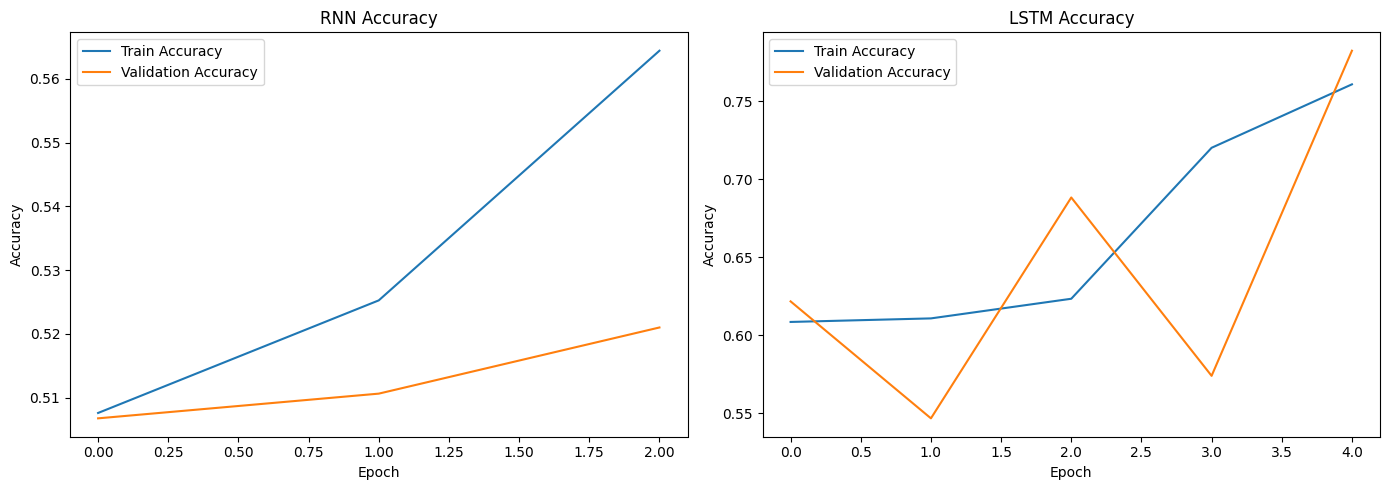

In [13]:
history_df = pd.DataFrame({
    "RNN accuracy": history_rnn.history.get("accuracy", []),
    "RNN val_accuracy": history_rnn.history.get("val_accuracy", []),
    "RNN loss": history_rnn.history.get("loss", []),
    "RNN val_loss": history_rnn.history.get("val_loss", []),
})

history_df_lstm = pd.DataFrame({
    "LSTM accuracy": history_lstm.history.get("accuracy", []),
    "LSTM val_accuracy": history_lstm.history.get("val_accuracy", []),
    "LSTM loss": history_lstm.history.get("loss", []),
    "LSTM val_loss": history_lstm.history.get("val_loss", []),
})

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history_rnn.history["accuracy"], label="Train Accuracy")
axes[0].plot(history_rnn.history["val_accuracy"], label="Validation Accuracy")
axes[0].set_title("RNN Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(history_lstm.history["accuracy"], label="Train Accuracy")
axes[1].plot(history_lstm.history["val_accuracy"], label="Validation Accuracy")
axes[1].set_title("LSTM Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

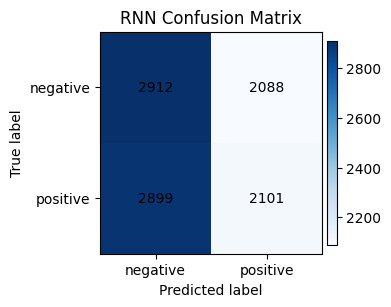

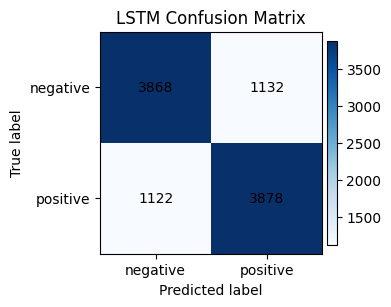

In [14]:
def plot_confusion_matrix(cm, title):
    fig, ax = plt.subplots(figsize=(3.8, 3.8), constrained_layout=True)
    im = ax.imshow(cm, cmap="Blues")
    ax.set_title(title)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(["negative", "positive"])
    ax.set_yticklabels(["negative", "positive"])

    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, cm[i, j], ha="center", va="center", color="black")

    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.02)
    plt.show()

plot_confusion_matrix(confusion_matrix(y_test, y_pred_rnn), "RNN Confusion Matrix")
plot_confusion_matrix(confusion_matrix(y_test, y_pred_lstm), "LSTM Confusion Matrix")

## VI. Comparative Analysis

The outputs below support the comparison section in the report.
- `comparison_table`: overall metrics and training stability
- `length_analysis`: sequence-length sensitivity
- validation curves and confusion matrices: model behavior and error patterns

In [15]:
rnn_history = pd.DataFrame(history_rnn.history)
lstm_history = pd.DataFrame(history_lstm.history)

def summarize_training(history_df):
    best_val_acc = history_df["val_accuracy"].max()
    best_epoch = int(history_df["val_accuracy"].idxmax() + 1)
    final_train_acc = history_df["accuracy"].iloc[-1]
    final_val_acc = history_df["val_accuracy"].iloc[-1]
    generalization_gap = final_train_acc - final_val_acc
    val_loss_volatility = history_df["val_loss"].std()
    return best_val_acc, best_epoch, generalization_gap, val_loss_volatility

comparison_table = pd.DataFrame([
    {
        "Model": "RNN",
        "Test Accuracy": rnn_metrics["Accuracy"],
        "Test Precision": rnn_metrics["Precision"],
        "Test Recall": rnn_metrics["Recall"],
        "Test F1": rnn_metrics["F1-Score"],
        "Best Val Accuracy": summarize_training(rnn_history)[0],
        "Epoch of Best Val Acc": summarize_training(rnn_history)[1],
        "Generalization Gap": summarize_training(rnn_history)[2],
        "Val Loss Volatility": summarize_training(rnn_history)[3],
    },
    {
        "Model": "LSTM",
        "Test Accuracy": lstm_metrics["Accuracy"],
        "Test Precision": lstm_metrics["Precision"],
        "Test Recall": lstm_metrics["Recall"],
        "Test F1": lstm_metrics["F1-Score"],
        "Best Val Accuracy": summarize_training(lstm_history)[0],
        "Epoch of Best Val Acc": summarize_training(lstm_history)[1],
        "Generalization Gap": summarize_training(lstm_history)[2],
        "Val Loss Volatility": summarize_training(lstm_history)[3],
    }
])

display(comparison_table.round(4))

,Model,Test Accuracy,Test Precision,Test Recall,Test F1,Best Val Accuracy,Epoch of Best Val Acc,Generalization Gap,Val Loss Volatility
0,RNN,0.5013,0.5016,0.4202,0.4573,0.5210,3,0.0434,0.0010
1,LSTM,0.7746,0.7741,0.7756,0.7748,0.7824,5,-0.0216,0.0652


,Length Bucket,Samples,RNN Accuracy,LSTM Accuracy,LSTM - RNN
0,<=50,230,0.5087,0.8174,0.3087
1,51-100,1004,0.4781,0.7988,0.3207
2,101-150,2596,0.5116,0.8159,0.3043
3,151-200,1968,0.5020,0.7937,0.2917
4,>200,4202,0.4998,0.7320,0.2323


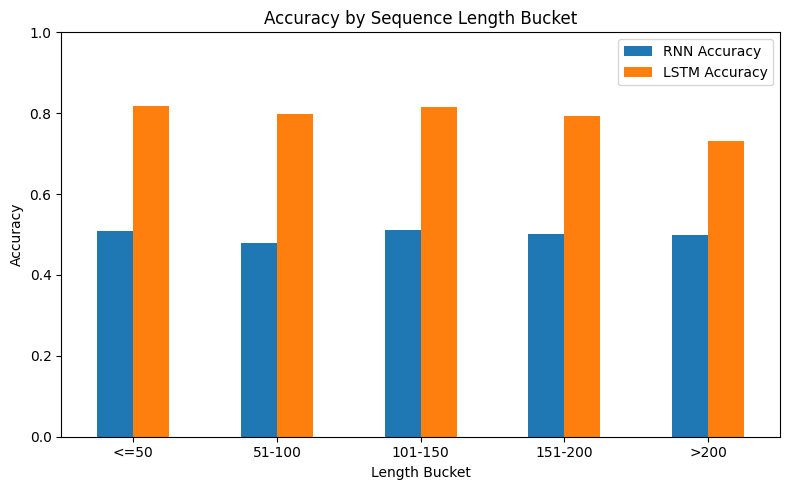

In [16]:
test_lengths = np.array([len(seq) for seq in X_test_sequences])

length_bins = [0, 50, 100, 150, 200, np.inf]
length_labels = ["<=50", "51-100", "101-150", "151-200", ">200"]
length_groups = pd.cut(test_lengths, bins=length_bins, labels=length_labels, include_lowest=True)

length_analysis_rows = []
for label in length_labels:
    idx = np.where(length_groups == label)[0]
    if len(idx) == 0:
        continue
    y_true = np.array(y_test)[idx]
    y_rnn = y_pred_rnn[idx]
    y_lstm = y_pred_lstm[idx]
    rnn_acc = accuracy_score(y_true, y_rnn)
    lstm_acc = accuracy_score(y_true, y_lstm)
    length_analysis_rows.append({
        "Length Bucket": label,
        "Samples": len(idx),
        "RNN Accuracy": rnn_acc,
        "LSTM Accuracy": lstm_acc,
        "LSTM - RNN": lstm_acc - rnn_acc
    })

length_analysis = pd.DataFrame(length_analysis_rows)
display(length_analysis.round(4))

ax = length_analysis.set_index("Length Bucket")[["RNN Accuracy", "LSTM Accuracy"]].plot(kind="bar", figsize=(8, 5))
ax.set_title("Accuracy by Sequence Length Bucket")
ax.set_ylabel("Accuracy")
ax.set_ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

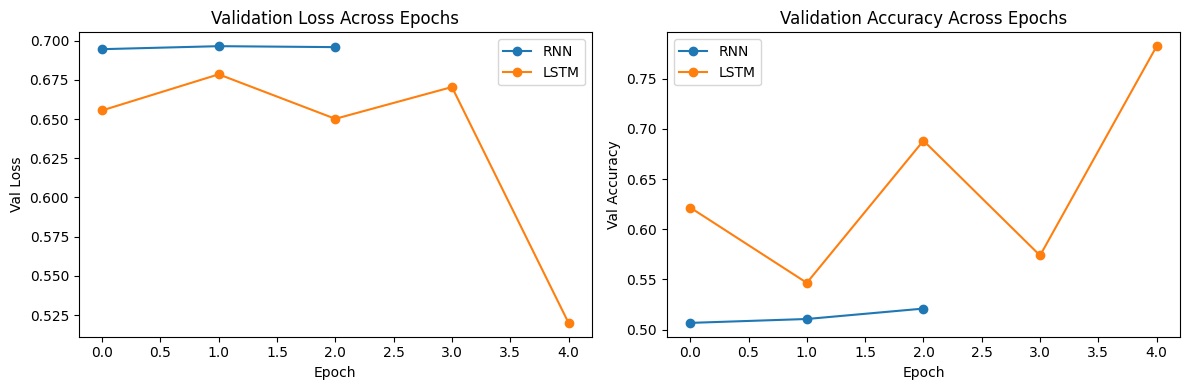

Training challenge notes:
- If validation loss oscillates heavily, that indicates less stable training dynamics.
- If the generalization gap is large, consider overfitting mitigation (dropout, stronger early stopping, fewer units).
- If longer sequences hurt RNN more than LSTM, this supports the long-term dependency explanation.


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(rnn_history["val_loss"], marker="o", label="RNN")
axes[0].plot(lstm_history["val_loss"], marker="o", label="LSTM")
axes[0].set_title("Validation Loss Across Epochs")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Val Loss")
axes[0].legend()

axes[1].plot(rnn_history["val_accuracy"], marker="o", label="RNN")
axes[1].plot(lstm_history["val_accuracy"], marker="o", label="LSTM")
axes[1].set_title("Validation Accuracy Across Epochs")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Val Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

print("Training challenge notes:")
print("- If validation loss oscillates heavily, that indicates less stable training dynamics.")
print("- If the generalization gap is large, consider overfitting mitigation (dropout, stronger early stopping, fewer units).")
print("- If longer sequences hurt RNN more than LSTM, this supports the long-term dependency explanation.")